# TP bandit à N bras

Les classes sont dans `bandit.py`, `players.py` et `simulation.py`. Les figures sont enregistrées dans `figures/`.

In [1]:
import inspect
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Code

from bandit import Bandit, Ban10
from players import GreedyPlayer, OptimistGreedyPlayer, UCBGreedyPlayer
from simulation import simulate

SEED = 42
random.seed(SEED)
os.makedirs("figures", exist_ok=True)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#888888",
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.8,
    "lines.linewidth": 1.6,
    "font.size": 10,
})

def show(obj):
    return Code(inspect.getsource(obj), language="python")

def normal_pdf(x, mu, sigma=1):
    return np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

## Exercice 1 — Le bandit manchot

Classes `Bandit` et `Ban10` :

In [2]:
import bandit
show(bandit)

import random


class Bandit:
    def __init__(self):
        self.avg = random.gauss(0, 1)

    def play(self):
        return random.gauss(self.avg, 1)


class Ban10:
    def __init__(self):
        self.bandits = [Bandit() for _ in range(10)]
        avgs = [b.avg for b in self.bandits]
        self.best_action = avgs.index(max(avgs))

    def play(self, action):
        return self.bandits[action].play()

### 1.3 — Distribution des gains d'un bandit

On joue 1000 fois le même bandit et on trace l'histogramme des gains, avec la densité théorique N(avg, 1) par-dessus.

avg du bandit = -0.144
moyenne observée = -0.161
variance observée = 1.040


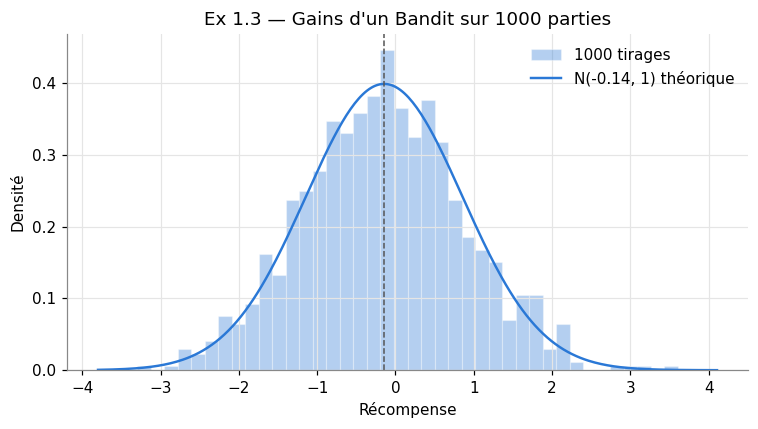

In [3]:
bandit = Bandit()
values = [bandit.play() for _ in range(1000)]
print(f"avg du bandit = {bandit.avg:.3f}")
print(f"moyenne observée = {np.mean(values):.3f}")
print(f"variance observée = {np.var(values):.3f}")

x = np.linspace(min(values) - 0.5, max(values) + 0.5, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(values, bins=40, density=True, color=COLORS[0], alpha=0.35,
        edgecolor="white", linewidth=0.8, label="1000 tirages")
ax.plot(x, normal_pdf(x, bandit.avg), color=COLORS[0],
        label=f"N({bandit.avg:.2f}, 1) théorique")
ax.axvline(bandit.avg, color="#555555", linestyle="--", linewidth=1)
ax.set_title("Ex 1.3 — Gains d'un Bandit sur 1000 parties")
ax.set_xlabel("Récompense")
ax.set_ylabel("Densité")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/ex1_3_un_bandit.png")
plt.show()

### 1.4 — Trois bandits

Même chose avec 3 bandits : on doit voir 3 pics centrés sur 3 espérances différentes.

Bandit 0 : avg = 0.889, moyenne observée = 0.875
Bandit 1 : avg = -2.653, moyenne observée = -2.619
Bandit 2 : avg = -0.761, moyenne observée = -0.784


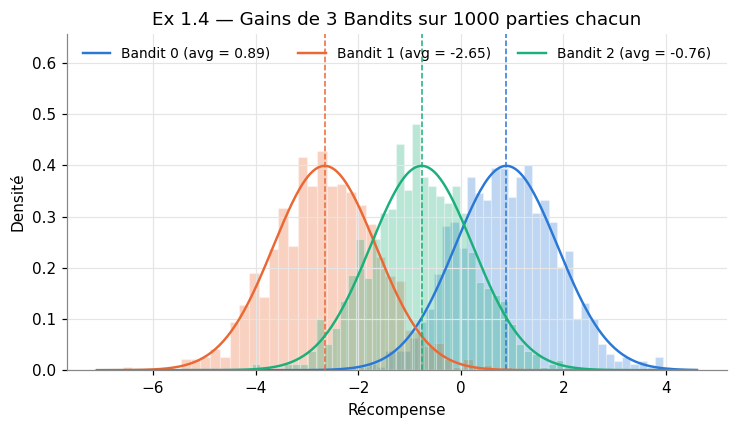

In [4]:
bandits = [Bandit() for _ in range(3)]
fig, ax = plt.subplots(figsize=(7, 4))
all_values = []
for i, b in enumerate(bandits):
    vals = [b.play() for _ in range(1000)]
    all_values += vals
    print(f"Bandit {i} : avg = {b.avg:.3f}, moyenne observée = {np.mean(vals):.3f}")
    ax.hist(vals, bins=40, density=True, color=COLORS[i], alpha=0.3,
            edgecolor="white", linewidth=0.8)

x = np.linspace(min(all_values) - 0.5, max(all_values) + 0.5, 300)
for i, b in enumerate(bandits):
    ax.plot(x, normal_pdf(x, b.avg), color=COLORS[i],
            label=f"Bandit {i} (avg = {b.avg:.2f})")
    ax.axvline(b.avg, color=COLORS[i], linestyle="--", linewidth=1)

ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
ax.set_title("Ex 1.4 — Gains de 3 Bandits sur 1000 parties chacun")
ax.set_xlabel("Récompense")
ax.set_ylabel("Densité")
ax.legend(frameon=False, ncol=3, loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig("figures/ex1_4_trois_bandits.png")
plt.show()

## Exercice 3 — Algorithme ε-greedy

### 3.1 – 3.2 — Constructeur

`n` et `eps` sont stockés, et les tableaux Q (`action_values`) et N (`eval_count`) sont initialisés à 0.

In [5]:
show(GreedyPlayer.__init__)

def __init__(self, n, eps):
        self.n = n
        self.eps = eps
        self.action_values = [0.0] * n  # Q
        self.eval_count = [0] * n       # N

In [6]:
player = GreedyPlayer(10, 0.1)
print("n =", player.n, "| eps =", player.eps)
print("action_values =", player.action_values)
print("eval_count    =", player.eval_count)

n = 10 | eps = 0.1
action_values = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
eval_count    = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### 3.3, 3.4 et 3.7 — `get_action`

On tire un nombre entre 0 et 1 : s'il est inférieur à ε, `explore` vaut `True` et on joue au hasard, sinon on joue l'action greedy.

In [7]:
show(GreedyPlayer.get_action)

def get_action(self):
        explore = random.random() < self.eps
        if explore:
            return self._random_action()
        return self._greedy_action()

### 3.5 — `_greedy_action`

Renvoie l'action de plus grande valeur estimée, au hasard parmi les ex æquo.

In [8]:
show(GreedyPlayer._greedy_action)

def _greedy_action(self):
        best = max(self.action_values)
        best_actions = [a for a in range(self.n) if self.action_values[a] == best]
        return random.choice(best_actions)

In [9]:
player = GreedyPlayer(10, 0.1)
player.action_values = [0, 1.5, 0.2, 1.5, -1, 0, 0, 1.5, 0, 0]
print("Q =", player.action_values)
print("10 appels à _greedy_action :", [player._greedy_action() for _ in range(10)])

Q = [0, 1.5, 0.2, 1.5, -1, 0, 0, 1.5, 0, 0]
10 appels à _greedy_action : [1, 7, 7, 3, 7, 3, 3, 1, 7, 7]


### 3.6 — `_random_action`

In [10]:
show(GreedyPlayer._random_action)

def _random_action(self):
        return random.randrange(self.n)

In [11]:
print("20 appels à _random_action :", [player._random_action() for _ in range(20)])

20 appels à _random_action : [6, 3, 7, 6, 5, 9, 9, 1, 6, 2, 4, 7, 3, 1, 4, 9, 8, 6, 4, 3]


### 3.7 — Vérification de la proportion d'exploration

Avec ε = 0.1 et Q comme ci-dessus, environ 90 % des actions doivent être 1, 3 ou 7, et le reste réparti sur les 10 bras.

In [12]:
actions = [player.get_action() for _ in range(10_000)]
counts = np.bincount(actions, minlength=10)
for a, c in enumerate(counts):
    print(f"action {a} : {c / len(actions):6.2%}")

action 0 :  0.95%
action 1 : 31.20%
action 2 :  1.09%
action 3 : 30.97%
action 4 :  0.90%
action 5 :  1.17%
action 6 :  1.08%
action 7 : 30.79%
action 8 :  0.93%
action 9 :  0.92%


### 3.8 — `reward`

Met à jour N puis Q pour l'action jouée, avec la moyenne incrémentale :
Q(a) ← Q(a) + (R − Q(a)) / N(a)

In [13]:
show(GreedyPlayer.reward)

def reward(self, action, value):
        self.eval_count[action] += 1
        q = self.action_values[action]
        self.action_values[action] = q + (value - q) / self.eval_count[action]

In [14]:
player = GreedyPlayer(10, 0.1)
for r in [1.0, 2.0, 3.0]:
    player.reward(4, r)
    q, n = player.action_values[4], player.eval_count[4]
    print(f"reward(4, {r}) -> Q[4] = {q:.3f}, N[4] = {n}")
print("moyenne attendue :", np.mean([1.0, 2.0, 3.0]))

reward(4, 1.0) -> Q[4] = 1.000, N[4] = 1
reward(4, 2.0) -> Q[4] = 1.500, N[4] = 2
reward(4, 3.0) -> Q[4] = 2.000, N[4] = 3
moyenne attendue : 2.0


## Exercice 5 — Initialisation optimiste

### 5.3 — Optimiste (Q₀ = 5, ε = 0) contre ε-greedy (ε = 0.1)

`OptimistGreedyPlayer` (5.1, 5.2) :

In [15]:
show(OptimistGreedyPlayer)

class OptimistGreedyPlayer(GreedyPlayer):
    def __init__(self, n, eps=0, q0=5):
        super().__init__(n, eps)
        self.action_values = [float(q0)] * n

2000 problèmes `Ban10`, 1000 étapes. Les deux joueurs jouent sur **les mêmes** objets `Ban10`, toutes les instances avancent étape par étape (fonction `simulate`).

In [16]:
show(simulate)

def simulate(players, runs=2000, steps=1000):
    """Fait jouer chaque type de joueur sur les mêmes `runs` Ban10, étape par étape.

    players : dict nom -> fonction qui crée un joueur
    Renvoie un dict nom -> (récompense moyenne, % de choix optimal) par étape.
    """
    bans = [Ban10() for _ in range(runs)]
    results = {}
    for name, make_player in players.items():
        instances = [make_player() for _ in range(runs)]
        rewards = np.zeros(steps)
        optimal = np.zeros(steps)
        for t in range(steps):
            for ban, player in zip(bans, instances):
                action = player.get_action()
                value = ban.play(action)
                player.reward(action, value)
                rewards[t] += value
                optimal[t] += action == ban.best_action
        results[name] = (rewards / runs, 100 * optimal / runs)
    return results

In [17]:
random.seed(SEED)
results_5 = simulate({
    "Optimiste, Q₀ = 5, ε = 0": lambda: OptimistGreedyPlayer(10, eps=0, q0=5),
    "ε-greedy, Q₀ = 0, ε = 0.1": lambda: GreedyPlayer(10, eps=0.1),
})

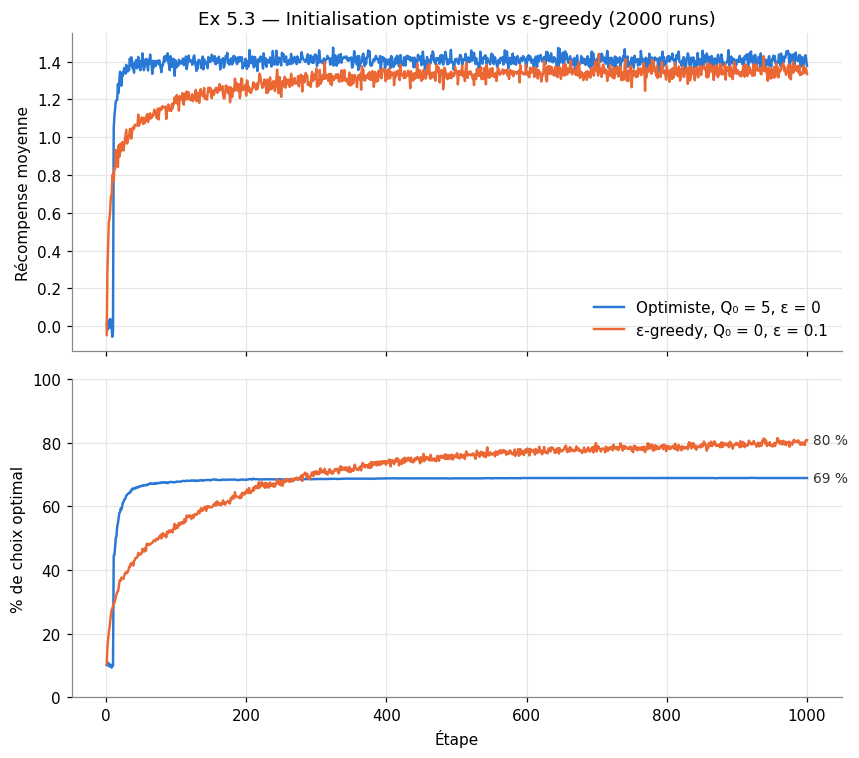

In [18]:
def plot_comparison(results, title, path):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    for i, (name, (rewards, optimal)) in enumerate(results.items()):
        steps = np.arange(1, len(rewards) + 1)
        ax1.plot(steps, rewards, color=COLORS[i], label=name)
        ax2.plot(steps, optimal, color=COLORS[i], label=name)
        ax2.annotate(f"{optimal[-50:].mean():.0f} %", (steps[-1], optimal[-1]),
                     xytext=(4, 0), textcoords="offset points",
                     va="center", fontsize=9, color="#333333")
    ax1.set_ylabel("Récompense moyenne")
    ax1.set_title(title)
    ax1.legend(frameon=False, loc="lower right")
    ax2.set_ylabel("% de choix optimal")
    ax2.set_xlabel("Étape")
    ax2.set_ylim(0, 100)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

plot_comparison(results_5, "Ex 5.3 — Initialisation optimiste vs ε-greedy (2000 runs)",
                "figures/ex5_3_optimiste_vs_greedy.png")

In [19]:
for name, (rewards, optimal) in results_5.items():
    print(f"{name:27s} | récompense moy. = {rewards[-200:].mean():.3f}"
          f" | % optimal = {optimal[-200:].mean():.1f} %  (200 dernières étapes)")

Optimiste, Q₀ = 5, ε = 0    | récompense moy. = 1.408 | % optimal = 68.9 %  (200 dernières étapes)
ε-greedy, Q₀ = 0, ε = 0.1   | récompense moy. = 1.350 | % optimal = 79.4 %  (200 dernières étapes)


## Exercice 6 — Sélection Upper-Confidence-Bound

### 6.1 — `UCBGreedyPlayer`

Hérite de `GreedyPlayer`, prend en plus `c` (degré d'exploration). On compte `t`, le nombre d'appels à `reward`.
Par défaut ε = 0 : c'est le terme de confiance qui gère l'exploration.

In [20]:
show(UCBGreedyPlayer.__init__)

def __init__(self, n, c=2, eps=0):
        super().__init__(n, eps)
        self.c = c
        self.t = 0

In [21]:
show(UCBGreedyPlayer.reward)

def reward(self, action, value):
        self.t += 1
        super().reward(action, value)

### 6.2 — `_greedy_action` surchargée

Formule du cours :

$$A_t = \underset{a}{\operatorname{argmax}} \left[ Q_t(a) + c \sqrt{\frac{\ln t}{N_t(a)}} \right]$$

Si N(a) = 0, l'action est considérée comme maximale : on joue d'abord chaque bras une fois.

In [22]:
show(UCBGreedyPlayer._greedy_action)

def _greedy_action(self):
        # une action jamais jouée est considérée comme maximale
        untried = [a for a in range(self.n) if self.eval_count[a] == 0]
        if untried:
            return random.choice(untried)

        log_t = math.log(self.t)
        scores = [
            self.action_values[a] + self.c * math.sqrt(log_t / self.eval_count[a])
            for a in range(self.n)
        ]
        best = max(scores)
        return random.choice([a for a in range(self.n) if scores[a] == best])

In [23]:
random.seed(SEED)
ban = Ban10()
ucb = UCBGreedyPlayer(10, c=2)
print("meilleur bras :", ban.best_action)
for t in range(15):
    a = ucb.get_action()
    r = ban.play(a)
    ucb.reward(a, r)
    print(f"t = {ucb.t:2d} | action = {a} | récompense = {r:+.2f}"
          f" | optimal = {a == ban.best_action}")

meilleur bras : 3
t =  1 | action = 8 | récompense = -1.25 | optimal = False
t =  2 | action = 9 | récompense = -0.65 | optimal = False
t =  3 | action = 7 | récompense = -1.81 | optimal = False
t =  4 | action = 6 | récompense = -0.64 | optimal = False
t =  5 | action = 3 | récompense = +0.39 | optimal = True
t =  6 | action = 2 | récompense = +0.38 | optimal = False
t =  7 | action = 5 | récompense = +0.09 | optimal = False
t =  8 | action = 0 | récompense = +0.96 | optimal = False
t =  9 | action = 1 | récompense = +0.79 | optimal = False
t = 10 | action = 4 | récompense = -0.29 | optimal = False
t = 11 | action = 0 | récompense = +0.55 | optimal = False
t = 12 | action = 1 | récompense = +0.03 | optimal = False
t = 13 | action = 3 | récompense = -0.10 | optimal = True
t = 14 | action = 2 | récompense = +0.64 | optimal = False
t = 15 | action = 5 | récompense = -2.25 | optimal = False


In [24]:
for _ in range(985):
    a = ucb.get_action()
    ucb.reward(a, ban.play(a))

print("Après 1000 coups :")
print("N =", ucb.eval_count)
print("Q =", [round(q, 2) for q in ucb.action_values])
print("vraies moyennes =", [round(b.avg, 2) for b in ban.bandits])

Après 1000 coups :
N = [25, 17, 30, 687, 22, 5, 118, 17, 35, 44]
Q = [-0.16, -0.45, -0.14, 0.69, -0.25, -1.57, 0.4, -0.41, -0.02, 0.08]
vraies moyennes = [-0.14, -0.17, -0.11, 0.7, -0.13, -1.5, 0.33, -0.27, -0.22, 0.12]
